In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Locate the project folder
PROJECT_DIR = Path.cwd().parent

# Define the dataset path
DATA_PATH = PROJECT_DIR / "data" / "train.csv"

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 913000
Number of columns: 4


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [4]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDate range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

print("\nUnique stores:", df["store"].nunique())
print("Unique items:", df["item"].nunique())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 27.9 MB

Missing values:
date     0
store    0
item     0
sales    0
dtype: int64

Duplicate rows: 0

Date range:
Start: 2013-01-01
End: 2017-12-31

Unique stores: 10
Unique items: 50


In [5]:
# Convert date column to datetime format
df["date"] = pd.to_datetime(df["date"])

# Sort data chronologically
df = df.sort_values(["date", "store", "item"]).reset_index(drop=True)

print("Date conversion completed.")
print("Date data type:", df["date"].dtype)
print("Earliest date:", df["date"].min())
print("Latest date:", df["date"].max())

Date conversion completed.
Date data type: datetime64[us]
Earliest date: 2013-01-01 00:00:00
Latest date: 2017-12-31 00:00:00


In [6]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSales summary:")
print(df["sales"].describe())

print("\nUnique dates:", df["date"].nunique())
print("Unique stores:", df["store"].nunique())
print("Unique items:", df["item"].nunique())

print("\nNegative sales rows:", (df["sales"] < 0).sum())

Dataset shape: (913000, 4)

Missing values:
date     0
store    0
item     0
sales    0
dtype: int64

Duplicate rows: 0

Sales summary:
count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64

Unique dates: 1826
Unique stores: 10
Unique items: 50

Negative sales rows: 0


In [7]:
# Check the number of records for each store-item combination
records_per_series = df.groupby(["store", "item"]).size()

print("Number of store-item combinations:", len(records_per_series))
print("\nRecords per combination:")
print(records_per_series.describe())

print("\nCombinations with unexpected record counts:")
print(records_per_series[records_per_series != df["date"].nunique()])

Number of store-item combinations: 500

Records per combination:
count     500.0
mean     1826.0
std         0.0
min      1826.0
25%      1826.0
50%      1826.0
75%      1826.0
max      1826.0
dtype: float64

Combinations with unexpected record counts:
Series([], dtype: int64)


In [8]:
# Aggregate sales across all stores and items
daily_sales = (
    df.groupby("date", as_index=False)["sales"]
      .sum()
      .sort_values("date")
)

print("Daily sales shape:", daily_sales.shape)
print("\nDaily sales summary:")
print(daily_sales["sales"].describe())

daily_sales.head()

Daily sales shape: (1826, 2)

Daily sales summary:
count     1826.000000
mean     26125.143483
std       6418.270181
min      11709.000000
25%      21195.000000
50%      25839.500000
75%      30779.500000
max      44936.000000
Name: sales, dtype: float64


,date,sales
0,2013-01-01,13696
1,2013-01-02,13678
2,2013-01-03,14488
3,2013-01-04,15677
4,2013-01-05,16237


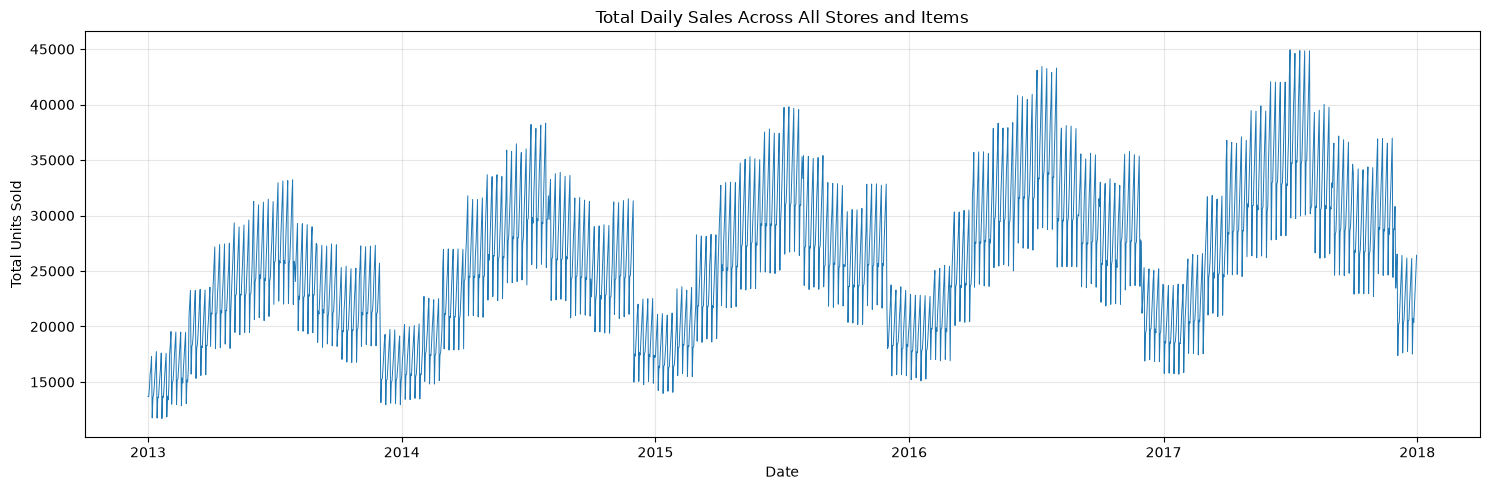

In [9]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"],
    linewidth=0.7
)

plt.title("Total Daily Sales Across All Stores and Items")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

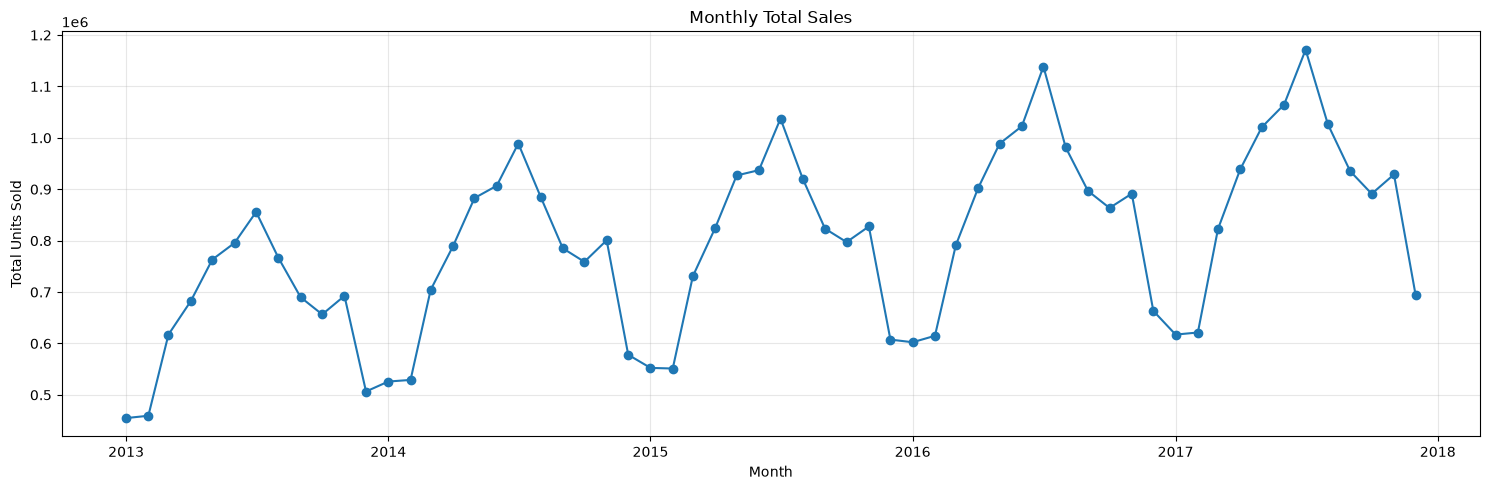

In [10]:
monthly_sales = (
    daily_sales.set_index("date")["sales"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(15, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Total Sales")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Extract weekday from each date
daily_sales["day_of_week"] = daily_sales["date"].dt.day_name()

# Calculate average total sales by weekday
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    daily_sales.groupby("day_of_week")["sales"]
    .mean()
    .reindex(weekday_order)
)

print("Average total daily sales by weekday:")
print(weekday_sales.round(2))

Average total daily sales by weekday:
day_of_week
Monday       20714.82
Tuesday      24112.95
Wednesday    24184.25
Thursday     25861.61
Friday       27578.62
Saturday     29331.35
Sunday       31071.67
Name: sales, dtype: float64


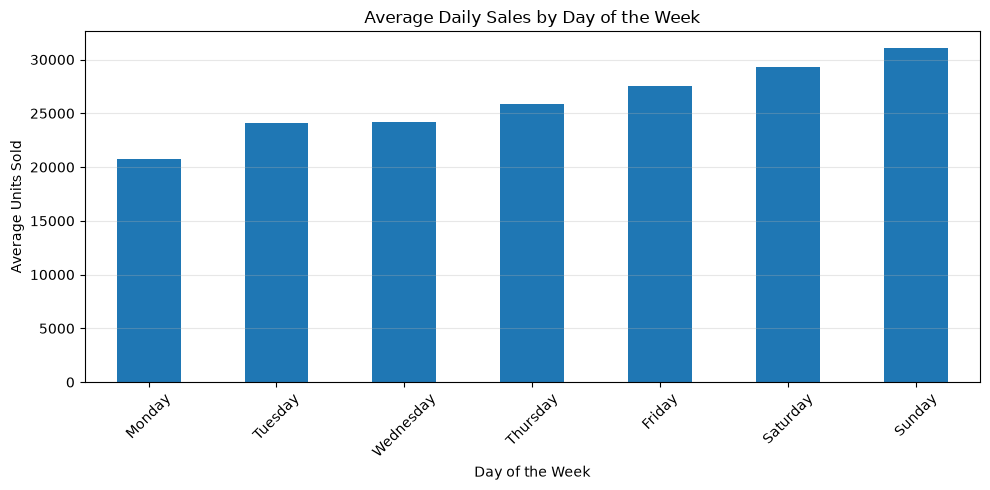

In [12]:
plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Daily Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
daily_sales["month"] = daily_sales["date"].dt.month

monthly_pattern = (
    daily_sales.groupby("month")["sales"]
    .mean()
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_pattern.index = month_names

print("Average total daily sales by month:")
print(monthly_pattern.round(2))

Average total daily sales by month:
Jan    17762.25
Feb    19689.20
Mar    23652.79
Apr    27576.45
May    29564.11
Jun    31512.74
Jul    33499.31
Aug    29552.61
Sep    27536.38
Oct    25596.90
Nov    27609.04
Dec    19682.63
Name: sales, dtype: float64


In [14]:
# Start from the daily aggregated sales
model_df = daily_sales[["date", "sales"]].copy()

# Extract calendar features
model_df["day_of_week"] = model_df["date"].dt.dayofweek
model_df["day_of_month"] = model_df["date"].dt.day
model_df["month"] = model_df["date"].dt.month
model_df["year"] = model_df["date"].dt.year
model_df["day_of_year"] = model_df["date"].dt.dayofyear

# Create lag features using past sales only
model_df["lag_1"] = model_df["sales"].shift(1)
model_df["lag_7"] = model_df["sales"].shift(7)
model_df["lag_28"] = model_df["sales"].shift(28)

# Create rolling averages from previous days only
model_df["rolling_mean_7"] = (
    model_df["sales"].shift(1).rolling(window=7).mean()
)

model_df["rolling_mean_28"] = (
    model_df["sales"].shift(1).rolling(window=28).mean()
)

print("Model dataset shape:", model_df.shape)
model_df.head(10)

Model dataset shape: (1826, 12)


C:\Users\DELL\AppData\Local\Temp\ipykernel_9080\161611873.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_df["day_of_week"] = model_df["date"].dt.dayofweek
C:\Users\DELL\AppData\Local\Temp\ipykernel_9080\161611873.py:9: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  model_df["day_of_year"] = model_df["date"].dt.dayofyear


,date,sales,day_of_week,day_of_month,month,year,day_of_year,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28
0,2013-01-01,13696,1,1,1,2013,1,NaN,NaN,NaN,NaN,NaN
1,2013-01-02,13678,2,2,1,2013,2,13696.0,NaN,NaN,NaN,NaN
2,2013-01-03,14488,3,3,1,2013,3,13678.0,NaN,NaN,NaN,NaN
3,2013-01-04,15677,4,4,1,2013,4,14488.0,NaN,NaN,NaN,NaN
4,2013-01-05,16237,5,5,1,2013,5,15677.0,NaN,NaN,NaN,NaN
5,2013-01-06,17291,6,6,1,2013,6,16237.0,NaN,NaN,NaN,NaN
6,2013-01-07,11769,0,7,1,2013,7,17291.0,NaN,NaN,NaN,NaN
7,2013-01-08,13560,1,8,1,2013,8,11769.0,13696.0,NaN,14690.857143,NaN
8,2013-01-09,13878,2,9,1,2013,9,13560.0,13678.0,NaN,14671.428571,NaN
9,2013-01-10,14642,3,10,1,2013,10,13878.0,14488.0,NaN,14700.000000,NaN


In [15]:
model_df = model_df.dropna().reset_index(drop=True)

print("Rows after removing unavailable lag features:", len(model_df))
print("First modeling date:", model_df["date"].min())
print("Last modeling date:", model_df["date"].max())

model_df.head()

Rows after removing unavailable lag features: 1798
First modeling date: 2013-01-29 00:00:00
Last modeling date: 2017-12-31 00:00:00


,date,sales,day_of_week,day_of_month,month,year,day_of_year,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28
0,2013-01-29,13724,1,29,1,2013,29,11848.0,13724.0,13696.0,14776.714286,14752.321429
1,2013-01-30,13391,2,30,1,2013,30,13724.0,13613.0,13678.0,14776.714286,14753.321429
2,2013-01-31,14724,3,31,1,2013,31,13391.0,14472.0,14488.0,14745.000000,14743.071429
3,2013-02-01,17473,4,1,2,2013,32,14724.0,15640.0,15677.0,14781.000000,14751.500000
4,2013-02-02,18323,5,2,2,2013,33,17473.0,16561.0,16237.0,15042.857143,14815.642857


In [16]:
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nTraining rows:", len(train_df))
print("Testing rows:", len(test_df))

Training period:
2013-01-29 00:00:00 to 2017-01-05 00:00:00

Testing period:
2017-01-06 00:00:00 to 2017-12-31 00:00:00

Training rows: 1438
Testing rows: 360


In [17]:
# Baseline: predict sales using the same weekday one week earlier
y_test = test_df["sales"].to_numpy()
baseline_predictions = test_df["lag_7"].to_numpy()

print("Actual sales (first 10 test days):")
print(y_test[:10])

print("\nBaseline predictions (first 10 test days):")
print(baseline_predictions[:10])

Actual sales (first 10 test days):
[20994 22591 23700 15797 18608 18491 19684 21186 22434 23701]

Baseline predictions (first 10 test days):
[22296. 23792. 23709. 15772. 18650. 18510. 19895. 20994. 22591. 23700.]


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = np.abs(actual - predicted).sum() / np.abs(actual).sum() * 100

    return {
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WAPE (%)": round(wape, 2)
    }

baseline_results = evaluate_forecast(
    y_test,
    baseline_predictions,
    "7-day seasonal naive baseline"
)

print(baseline_results)

{'Model': '7-day seasonal naive baseline', 'MAE': 899.81, 'RMSE': np.float64(1876.62), 'WAPE (%)': np.float64(3.05)}


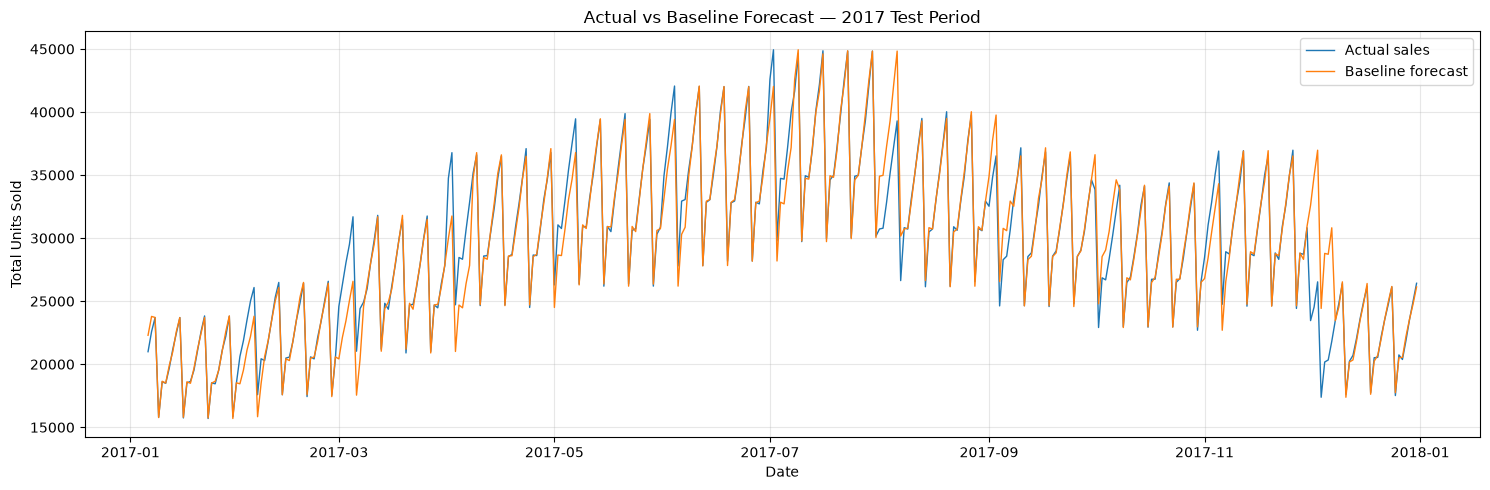

In [19]:
plt.figure(figsize=(15, 5))

plt.plot(
    test_df["date"],
    y_test,
    label="Actual sales",
    linewidth=1
)

plt.plot(
    test_df["date"],
    baseline_predictions,
    label="Baseline forecast",
    linewidth=1
)

plt.title("Actual vs Baseline Forecast — 2017 Test Period")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.ensemble import RandomForestRegressor

features = [
    "day_of_week",
    "day_of_month",
    "month",
    "year",
    "day_of_year",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

X_train = train_df[features]
y_train = train_df["sales"]

X_test = test_df[features]
y_test = test_df["sales"]

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest training completed!")
print("Number of features:", len(features))
print("Predictions generated:", len(rf_predictions))

Random Forest training completed!
Number of features: 10
Predictions generated: 360


In [21]:
rf_results = evaluate_forecast(
    y_test.to_numpy(),
    rf_predictions,
    "Random Forest"
)

print(rf_results)

{'Model': 'Random Forest', 'MAE': 639.78, 'RMSE': np.float64(1093.93), 'WAPE (%)': np.float64(2.17)}


In [22]:
comparison = pd.DataFrame([
    baseline_results,
    rf_results
])

display(comparison)


,Model,MAE,RMSE,WAPE (%)
0,7-day seasonal naive baseline,899.81,1876.62,3.05
1,Random Forest,639.78,1093.93,2.17


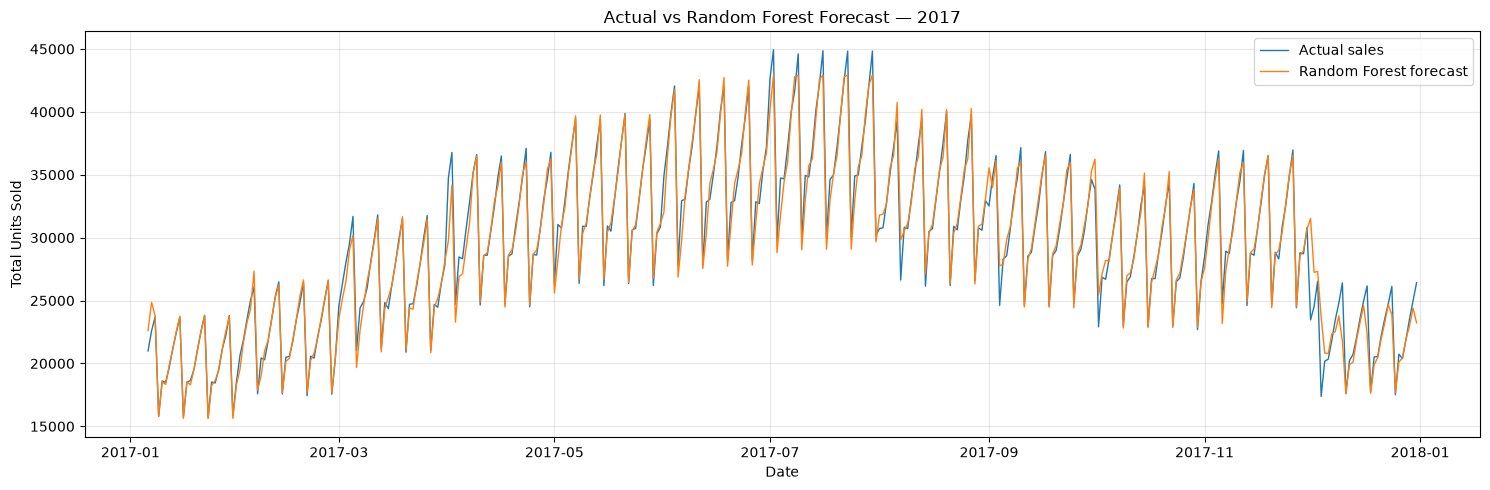

In [23]:
plt.figure(figsize=(15, 5))

plt.plot(
    test_df["date"],
    y_test,
    label="Actual sales",
    linewidth=1
)

plt.plot(
    test_df["date"],
    rf_predictions,
    label="Random Forest forecast",
    linewidth=1
)

plt.title("Actual vs Random Forest Forecast — 2017")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:
# Get feature importance from the trained Random Forest
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
6,lag_7,0.889586
5,lag_1,0.076884
2,month,0.009556
1,day_of_month,0.009309
4,day_of_year,0.007348
8,rolling_mean_7,0.002265
0,day_of_week,0.002069
7,lag_28,0.001907
9,rolling_mean_28,0.000832
3,year,0.000243


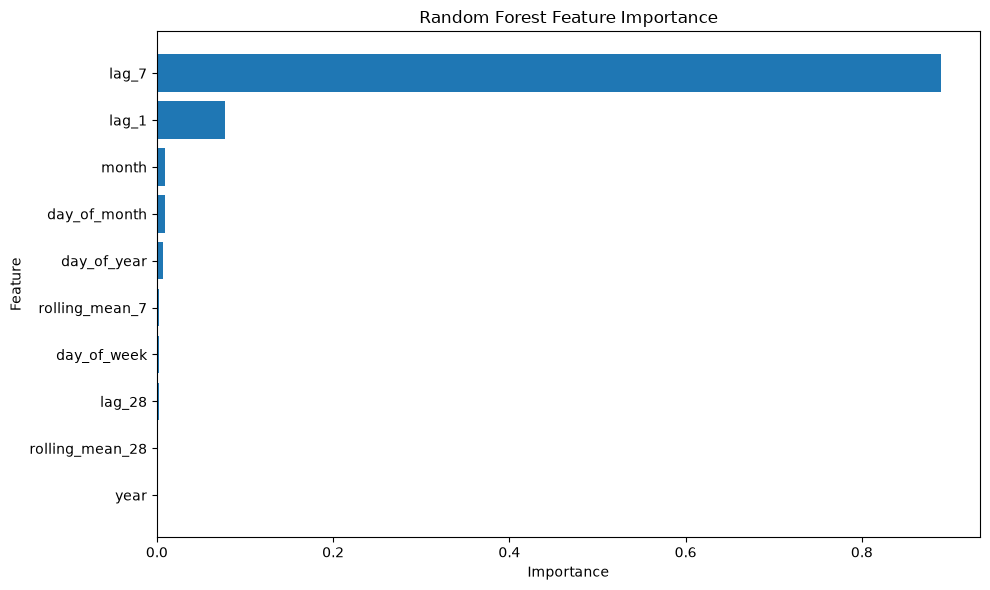

In [25]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [26]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(exist_ok=True)

comparison.to_csv(
    REPORTS_DIR / "model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    REPORTS_DIR / "feature_importance.csv",
    index=False
)

print("Saved model comparison and feature importance.")
print("Reports folder:", REPORTS_DIR)

Saved model comparison and feature importance.
Reports folder: c:\Users\DELL\Documents\retail-demand-forecasting\reports


In [27]:
from sklearn.tree import DecisionTreeRegressor

# Train a simple decision tree using only the previous week's sales
lag7_model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=10,
    random_state=42
)

lag7_model.fit(
    train_df[["lag_7"]],
    train_df["sales"]
)

lag7_predictions = lag7_model.predict(
    test_df[["lag_7"]]
)

lag7_results = evaluate_forecast(
    test_df["sales"].to_numpy(),
    lag7_predictions,
    "Decision Tree (lag_7 only)"
)

comparison = pd.DataFrame([
    baseline_results,
    lag7_results,
    rf_results
])

display(comparison)

,Model,MAE,RMSE,WAPE (%)
0,7-day seasonal naive baseline,899.81,1876.62,3.05
1,Decision Tree (lag_7 only),1156.49,1971.39,3.91
2,Random Forest,639.78,1093.93,2.17


In [28]:
comparison.to_csv(
    REPORTS_DIR / "model_comparison.csv",
    index=False
)

print("Updated model comparison saved.")

Updated model comparison saved.


### Forecasting Evaluation Approach

The dataset was split chronologically, with historical data used for training and the later period used for testing.

The initial experiment evaluates rolling one-day-ahead predictions using lag features and rolling averages derived from historical sales. This setup assumes actual sales become available before each subsequent day's forecast is generated.

The Random Forest achieved a preliminary MAE of 639.78, RMSE of 1,093.93, and WAPE of 2.17% on the test period. These results outperform the 7-day seasonal naive baseline under the current evaluation setup.

Further validation is required before treating these metrics as final portfolio results, particularly if the intended use case is forecasting multiple future days without access to actual sales during the forecast horizon.

In [29]:
import joblib

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)

joblib.dump(
    rf_model,
    MODELS_DIR / "retail_demand_random_forest.joblib"
)

print("Model saved successfully.")
print("Location:", MODELS_DIR / "retail_demand_random_forest.joblib")

Model saved successfully.
Location: c:\Users\DELL\Documents\retail-demand-forecasting\models\retail_demand_random_forest.joblib


## Rolling-Origin Backtesting

This section evaluates the forecasting models across multiple chronological test windows. At each forecast date, historical sales available before that date are used to construct lag and rolling-average features. This represents a rolling one-day-ahead forecasting scenario.

In [30]:
# Define the number of days in each test window
test_window = 90

# Define how many days to move forward between test windows
step_size = 90

# Find the first and last dates in our prepared dataset
start_date = model_df["date"].min()
end_date = model_df["date"].max()

print("Dataset starts:", start_date)
print("Dataset ends:", end_date)
print("Test window (days):", test_window)
print("Step size (days):", step_size)
print("Total prepared rows:", len(model_df))

Dataset starts: 2013-01-29 00:00:00
Dataset ends: 2017-12-31 00:00:00
Test window (days): 90
Step size (days): 90
Total prepared rows: 1798


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Features used by the existing Random Forest model
features = [
    "day_of_week",
    "day_of_month",
    "month",
    "year",
    "day_of_year",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
]

# Ensure rows are in chronological order
backtest_df = model_df.sort_values("date").reset_index(drop=True)

# Start with enough history for the first 90-day test window
initial_train_size = len(backtest_df) - 4 * test_window

results = []

for start in range(
    initial_train_size,
    len(backtest_df) - test_window + 1,
    step_size
):
    train = backtest_df.iloc[:start].copy()
    test = backtest_df.iloc[start:start + test_window].copy()

    # Train a fresh model using only data available before this window
    from sklearn.ensemble import RandomForestRegressor

    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )

    model.fit(train[features], train["sales"])

    # Predict the next 90 days using the prepared lag features
    rf_predictions = model.predict(test[features])

    # Seasonal-naive forecast: use sales from seven days earlier
    naive_predictions = test["lag_7"].to_numpy()

    actual = test["sales"].to_numpy()

    results.append({
        "test_start": test["date"].min(),
        "test_end": test["date"].max(),
        "train_rows": len(train),
        "test_rows": len(test),
        "rf_mae": mean_absolute_error(actual, rf_predictions),
        "naive_mae": mean_absolute_error(actual, naive_predictions),
        "rf_rmse": np.sqrt(mean_squared_error(actual, rf_predictions)),
        "naive_rmse": np.sqrt(mean_squared_error(actual, naive_predictions)),
        "rf_wape_pct": (
            np.abs(actual - rf_predictions).sum() / np.abs(actual).sum()
        ) * 100,
        "naive_wape_pct": (
            np.abs(actual - naive_predictions).sum() / np.abs(actual).sum()
        ) * 100
    })

backtest_results = pd.DataFrame(results)

backtest_results

,test_start,test_end,train_rows,test_rows,rf_mae,naive_mae,rf_rmse,naive_rmse,rf_wape_pct,naive_wape_pct
0,2017-01-06,2017-04-05,1438,90,487.551652,892.344444,871.586383,1709.561480,2.071913,3.792131
1,2017-04-06,2017-07-04,1528,90,589.919520,721.588889,893.739636,1273.515489,1.756185,2.148164
2,2017-07-05,2017-10-02,1618,90,743.069255,830.677778,1112.883136,1545.531735,2.201487,2.461045
3,2017-10-03,2017-12-31,1708,90,724.657501,1154.644444,1478.530621,2674.646116,2.652902,4.227043


In [32]:
# Save the results in the project's reports folder
backtest_report_path = REPORTS_DIR / "rolling_backtest_results.csv"

backtest_results.to_csv(backtest_report_path, index=False)

print("Backtesting results saved to:", backtest_report_path)

# Summarize average performance across the four windows
summary = backtest_results[
    [
        "rf_mae",
        "naive_mae",
        "rf_rmse",
        "naive_rmse",
        "rf_wape_pct",
        "naive_wape_pct",
    ]
].mean()

print("\nAverage metrics across the four test windows:")
print(summary.round(3))

Backtesting results saved to: c:\Users\DELL\Documents\retail-demand-forecasting\reports\rolling_backtest_results.csv

Average metrics across the four test windows:
rf_mae             636.299
naive_mae          899.814
rf_rmse           1089.185
naive_rmse        1800.814
rf_wape_pct          2.171
naive_wape_pct       3.157
dtype: float64
